In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

results_dir = root / "results"
figures_dir = results_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

historical = pd.read_csv(
    results_dir / "historical_var_es_forecasts.csv",
    parse_dates=["Date"]
)

parametric = pd.read_csv(
    results_dir / "parametric_var_es_forecasts.csv",
    parse_dates=["Date"]
)

monte_carlo = pd.read_csv(
    results_dir / "monte_carlo_var_es_forecasts.csv",
    parse_dates=["Date"]
)

assert historical["Date"].equals(parametric["Date"])
assert historical["Date"].equals(monte_carlo["Date"])

actual_loss = -historical["actual_return"]

print("Data loaded successfully!")
print("Forecast days:", len(historical))

Data loaded successfully!
Forecast days: 3732


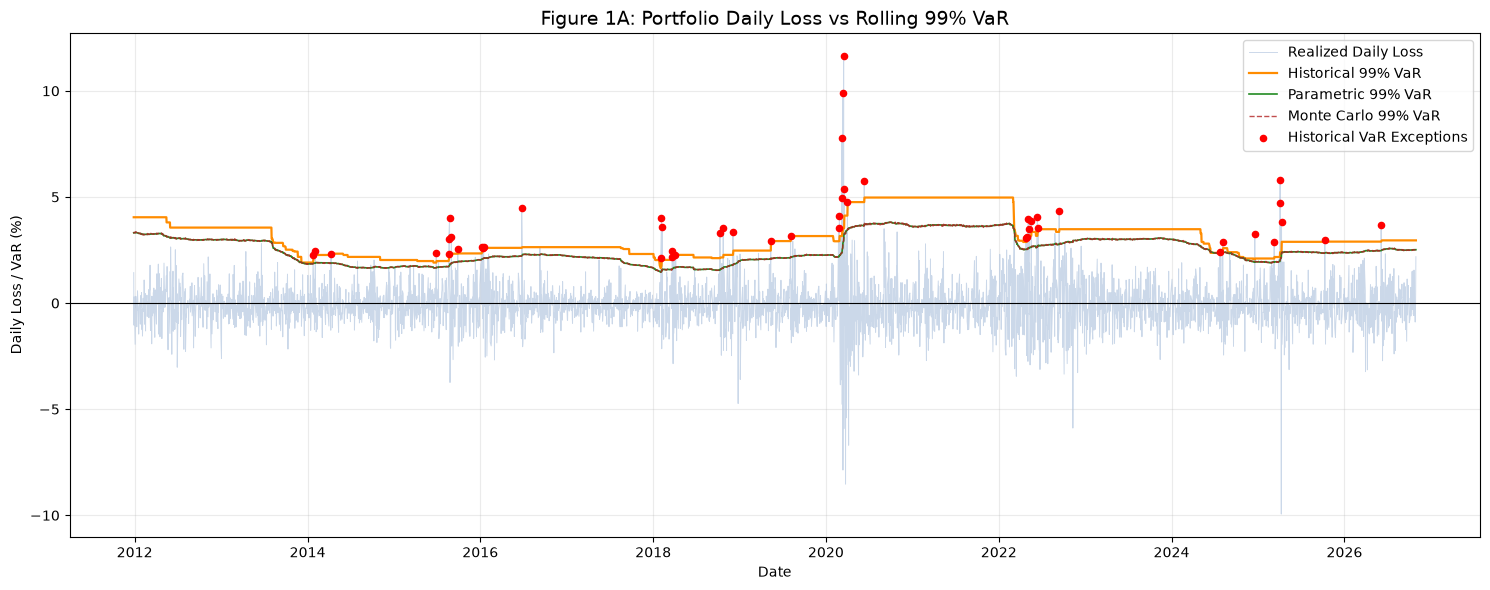

Forecast Days: 3732
Historical 99% Exceptions: 50
Figure 1A saved successfully!


In [3]:

# Figure 1A: Full-Sample Rolling 99% VaR

# Identify Historical VaR exceptions
exceptions = actual_loss > historical["var_99"]

fig, ax = plt.subplots(figsize=(15, 6))

# Realized portfolio losses
ax.plot(
    historical["Date"],
    actual_loss * 100,
    label="Realized Daily Loss",
    color="lightsteelblue",
    linewidth=0.7,
    alpha=0.65
)

# Historical Simulation
ax.plot(
    historical["Date"],
    historical["var_99"] * 100,
    label="Historical 99% VaR",
    color="darkorange",
    linewidth=1.6
)

# Parametric Normal
ax.plot(
    parametric["Date"],
    parametric["var_99"] * 100,
    label="Parametric 99% VaR",
    color="forestgreen",
    linewidth=1.2
)

# Monte Carlo Normal
ax.plot(
    monte_carlo["Date"],
    monte_carlo["var_99"] * 100,
    label="Monte Carlo 99% VaR",
    color="firebrick",
    linestyle="--",
    linewidth=1.0,
    alpha=0.8
)

# Highlight Historical VaR exceptions
ax.scatter(
    historical.loc[exceptions, "Date"],
    actual_loss.loc[exceptions] * 100,
    color="red",
    s=20,
    label="Historical VaR Exceptions",
    zorder=5
)

# Reference line
ax.axhline(
    0,
    color="black",
    linewidth=0.8
)

# Labels
ax.set_title(
    "Figure 1A: Portfolio Daily Loss vs Rolling 99% VaR",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily Loss / VaR (%)")

ax.legend(loc="upper right")
ax.grid(alpha=0.25)

plt.tight_layout()

# Save figure
plt.savefig(
    figures_dir / "rolling_var_99_full_sample.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Forecast Days:", len(historical))
print("Historical 99% Exceptions:", exceptions.sum())
print("Figure 1A saved successfully!")


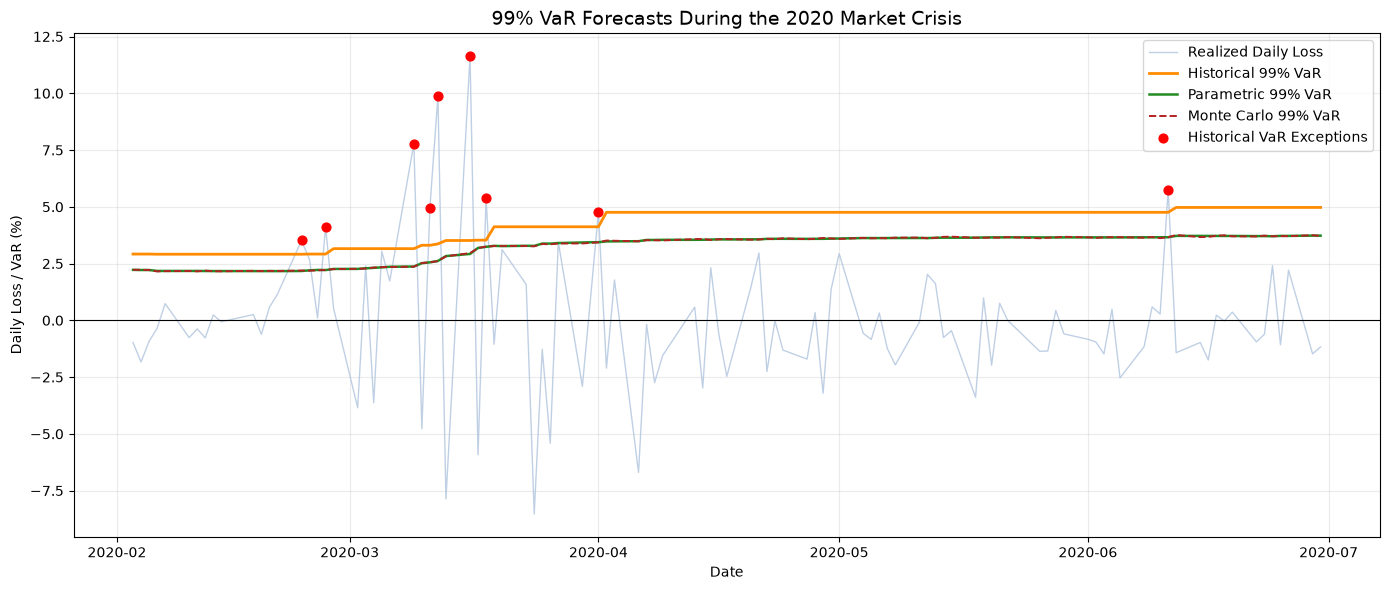

2020 trading days: 104
Historical exceptions: 9


In [2]:

# Figure 1B: 2020 Crisis Zoom

start_date = "2020-02-01"
end_date = "2020-06-30"

mask = historical["Date"].between(start_date, end_date)

dates = historical.loc[mask, "Date"]

loss_2020 = actual_loss.loc[mask]
hs_var_2020 = historical.loc[mask, "var_99"]
param_var_2020 = parametric.loc[mask, "var_99"]
mc_var_2020 = monte_carlo.loc[mask, "var_99"]

exceptions_2020 = loss_2020 > hs_var_2020

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    dates,
    loss_2020 * 100,
    label="Realized Daily Loss",
    color="lightsteelblue",
    linewidth=1.0,
    alpha=0.8
)

ax.plot(
    dates,
    hs_var_2020 * 100,
    label="Historical 99% VaR",
    color="darkorange",
    linewidth=2
)

ax.plot(
    dates,
    param_var_2020 * 100,
    label="Parametric 99% VaR",
    color="forestgreen",
    linewidth=1.8
)

ax.plot(
    dates,
    mc_var_2020 * 100,
    label="Monte Carlo 99% VaR",
    color="firebrick",
    linestyle="--",
    linewidth=1.4
)

ax.scatter(
    dates.loc[exceptions_2020],
    loss_2020.loc[exceptions_2020] * 100,
    color="red",
    s=40,
    label="Historical VaR Exceptions",
    zorder=5
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(
    "99% VaR Forecasts During the 2020 Market Crisis",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily Loss / VaR (%)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    figures_dir / "var_99_2020_crisis_zoom.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("2020 trading days:", mask.sum())
print("Historical exceptions:", exceptions_2020.sum())


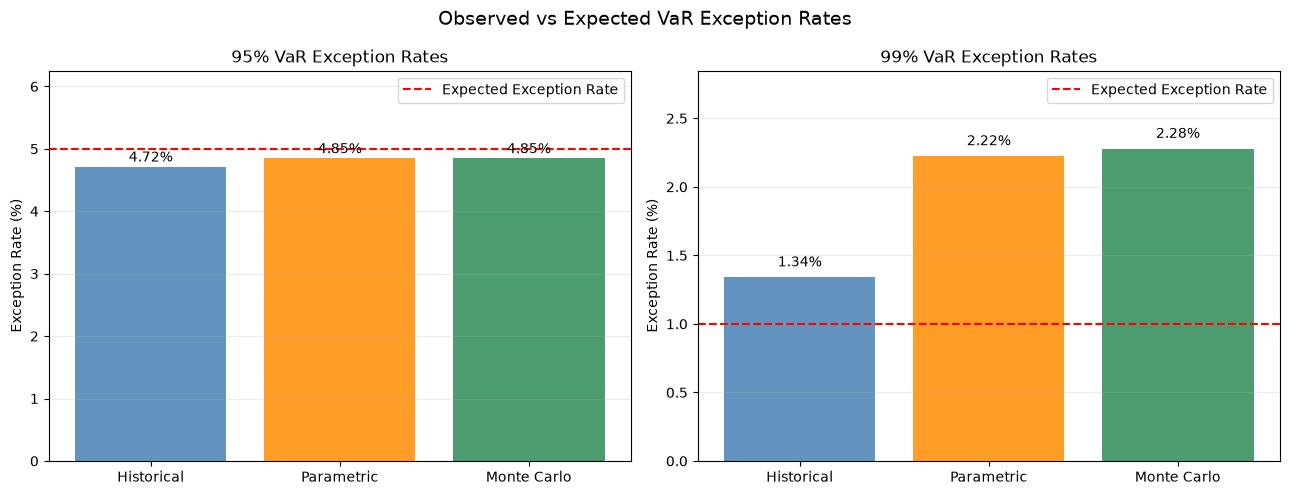

In [4]:

# Figure 2: VaR Exception Rate Comparison

summary = pd.read_csv(
    results_dir / "var_backtesting_summary.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

model_names = ["Historical", "Parametric", "Monte Carlo"]
bar_colors = ["steelblue", "darkorange", "seagreen"]

for ax, confidence, expected_rate in zip(
    axes,
    ["95%", "99%"],
    [0.05, 0.01]
):

    current = summary[
        summary["Confidence"] == confidence
    ].set_index("Model").loc[model_names]

    rates = current["Exception_Rate"] * 100

    bars = ax.bar(
        model_names,
        rates,
        color=bar_colors,
        alpha=0.85
    )

    ax.axhline(
        expected_rate * 100,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Expected Exception Rate"
    )

    for bar, rate in zip(bars, rates):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.08,
            f"{rate:.2f}%",
            ha="center"
        )

    ax.set_title(f"{confidence} VaR Exception Rates")
    ax.set_ylabel("Exception Rate (%)")
    ax.set_ylim(
        0,
        max(rates.max(), expected_rate * 100) * 1.25
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Observed vs Expected VaR Exception Rates",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    figures_dir / "var_exception_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


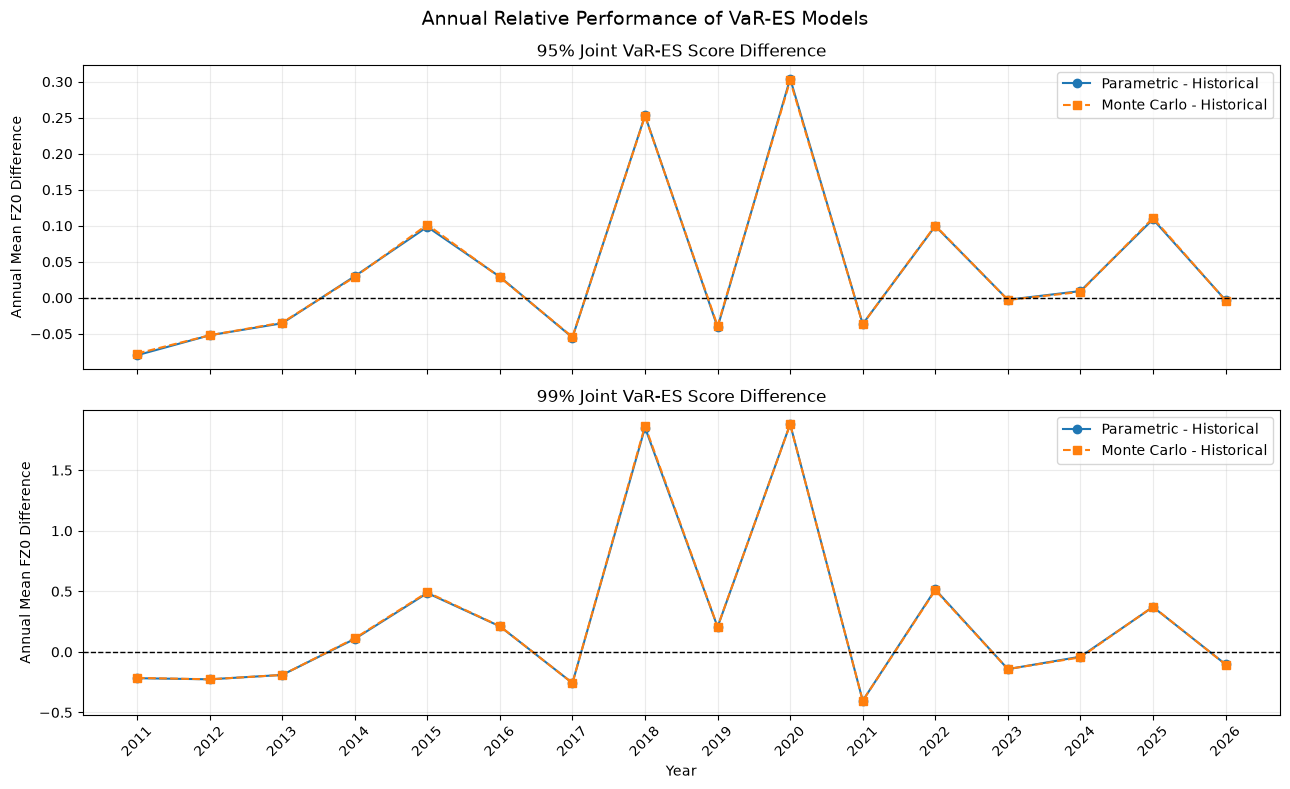

In [5]:

# Figure 3: Annual FZ0 Score Differences

import sys

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.backtesting import joint_var_es_score

models = {
    "Historical": historical,
    "Parametric": parametric,
    "Monte Carlo": monte_carlo
}

annual_results = []

for confidence in [0.95, 0.99]:

    level = int(round(confidence * 100))

    for name, df in models.items():

        scores = joint_var_es_score(
            actual_loss=-df["actual_return"].to_numpy(),
            var_forecast=df[f"var_{level}"].to_numpy(),
            es_forecast=df[f"es_{level}"].to_numpy(),
            confidence_level=confidence
        )

        temp = pd.DataFrame({
            "Date": df["Date"],
            "Model": name,
            "Confidence": f"{level}%",
            "FZ0": scores
        })

        temp["Year"] = temp["Date"].dt.year

        annual_results.append(temp)

annual_scores_df = pd.concat(
    annual_results,
    ignore_index=True
)

annual_pivot = annual_scores_df.pivot_table(
    index=["Year", "Confidence"],
    columns="Model",
    values="FZ0",
    aggfunc="mean"
)

annual_pivot["Parametric - Historical"] = (
    annual_pivot["Parametric"]
    - annual_pivot["Historical"]
)

annual_pivot["Monte Carlo - Historical"] = (
    annual_pivot["Monte Carlo"]
    - annual_pivot["Historical"]
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True
)

for ax, confidence in zip(axes, ["95%", "99%"]):

    current = annual_pivot.xs(
        confidence,
        level="Confidence"
    )

    ax.plot(
        current.index,
        current["Parametric - Historical"],
        marker="o",
        label="Parametric - Historical"
    )

    ax.plot(
        current.index,
        current["Monte Carlo - Historical"],
        marker="s",
        linestyle="--",
        label="Monte Carlo - Historical"
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{confidence} Joint VaR-ES Score Difference"
    )

    ax.set_ylabel("Annual Mean FZ0 Difference")
    ax.legend()
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(sorted(annual_pivot.index.get_level_values("Year").unique()))
axes[-1].tick_params(axis="x", rotation=45)

plt.suptitle(
    "Annual Relative Performance of VaR-ES Models",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    figures_dir / "annual_fz0_score_differences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Scenario                             Exclude 2018  Exclude 2020  Exclude Both  \
Confidence Comparison                                                           
95%        Monte Carlo - Historical        0.0331        0.0294        0.0121   
           Parametric - Historical         0.0329        0.0291        0.0116   
99%        Monte Carlo - Historical        0.1765        0.1747        0.0431   
           Parametric - Historical         0.1765        0.1734        0.0429   

Scenario                             Full Sample  
Confidence Comparison                             
95%        Monte Carlo - Historical       0.0478  
           Parametric - Historical        0.0477  
99%        Monte Carlo - Historical       0.2902  
           Parametric - Historical        0.2892

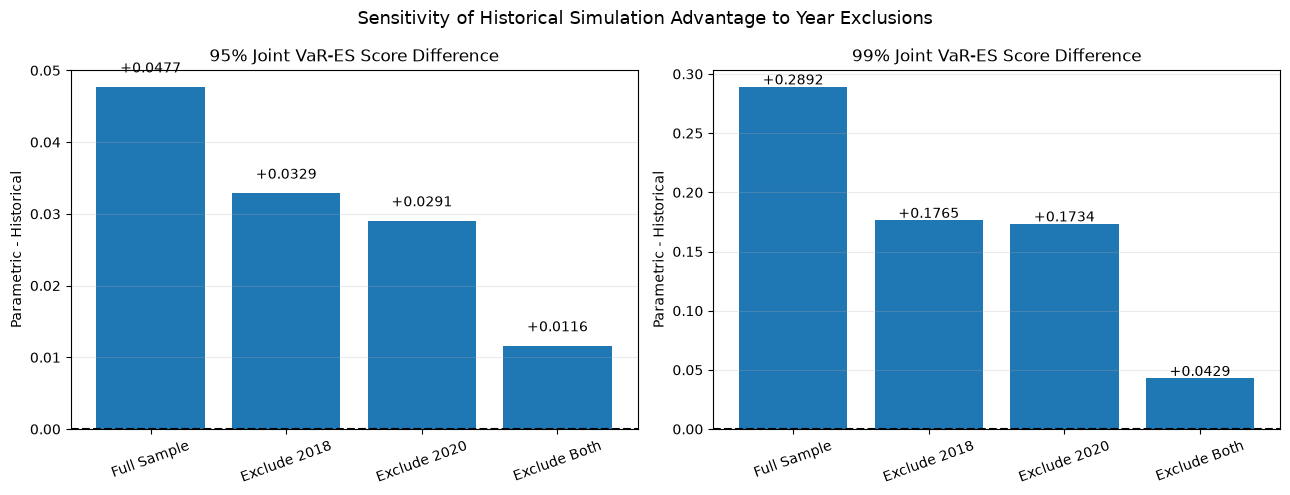

In [6]:

# Figure 4: Exclusion Robustness Analysis

daily_pivot = annual_scores_df.pivot(
    index=["Date", "Confidence"],
    columns="Model",
    values="FZ0"
)

exclusion_results = []

for confidence in ["95%", "99%"]:

    current = daily_pivot.xs(
        confidence,
        level="Confidence"
    ).sort_index()

    years = current.index.year

    scenarios = {
        "Full Sample": np.ones(len(current), dtype=bool),
        "Exclude 2018": years != 2018,
        "Exclude 2020": years != 2020,
        "Exclude Both": ~np.isin(years, [2018, 2020])
    }

    for model in ["Parametric", "Monte Carlo"]:

        differences = current[model] - current["Historical"]

        for scenario, mask in scenarios.items():

            exclusion_results.append({
                "Confidence": confidence,
                "Comparison": f"{model} - Historical",
                "Scenario": scenario,
                "Mean Difference": differences[mask].mean()
            })

exclusion_plot_df = pd.DataFrame(exclusion_results)

# Display the values before plotting
display(
    exclusion_plot_df.pivot_table(
        index=["Confidence", "Comparison"],
        columns="Scenario",
        values="Mean Difference"
    ).round(4)
)

# Plot Parametric vs Historical for clarity
plot_data = exclusion_plot_df[
    exclusion_plot_df["Comparison"] == "Parametric - Historical"
]

scenario_order = [
    "Full Sample",
    "Exclude 2018",
    "Exclude 2020",
    "Exclude Both"
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, confidence in zip(axes, ["95%", "99%"]):

    current = plot_data[
        plot_data["Confidence"] == confidence
    ].set_index("Scenario").loc[scenario_order]

    bars = ax.bar(
        scenario_order,
        current["Mean Difference"]
    )

    ax.axhline(0, color="black", linestyle="--")

    for bar, value in zip(
        bars, current["Mean Difference"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.002,
            f"{value:+.4f}",
            ha="center"
        )

    ax.set_title(f"{confidence} Joint VaR-ES Score Difference")
    ax.set_ylabel("Parametric - Historical")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Sensitivity of Historical Simulation Advantage to Year Exclusions",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    figures_dir / "fz0_exclusion_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
